# Pretrained feature: ResNet-50 (ImageNet) embeddings + logistic regression

This notebook asks: **does a neural network trained on ordinary photos describe our maps well enough to predict their scale - better than guessing, and better than the simple features in `3-simple_model`?**

The idea in one paragraph: we do **not** train a neural network. We borrow one that someone else already trained on about 1.2 million labeled photos (ImageNet), run each map through it, and keep the 2,048 numbers it computes right before its final answer. Those 2,048 numbers are the map's **embedding**. They become the feature vector for the same kind of logistic regression used in `3-simple_model`. Using a trained network this way, without changing its weights, is called **transfer learning by feature extraction**.

```
map (672 x 1024 PNG from 1-preprocessing)
  -> resize to 224 x 341, scale the colors the way the network expects     (section 5)
  -> ResNet-50 with ImageNet weights, frozen                                (sections 4, 6)
  -> 2,048-number embedding = output of the penultimate (second-to-last) layer
  -> standardize -> PCA (optional) -> logistic regression (softmax)         (sections 9-10)
  -> Small / Medium / Large
```

| Decision | Choice | Why |
|---|---|---|
| Network | ResNet-50, ImageNet weights (`IMAGENET1K_V2`), frozen | The standard pretrained CNN; the course examples use ResNet / VGG |
| Layer | Penultimate: global average pool, 2,048 numbers | The last layer before the part that only knows ImageNet's 1,000 categories |
| Input size | 224 wide x 341 tall, whole page, no crop | Close to the size the network was trained at; keeps the map's shape |
| PCA | 16 to 512 components, or none (all 2,048), chosen on val | Fewer numbers = faster, less room to overfit |
| Class weighting | none or `balanced`, chosen on val | Same as `3-simple_model` |
| C | 13 values from 1e-6 to 100, chosen on val | Same grid as `3-simple_model` |
| Choosing the setting | Simplest setting within one standard error of the best val score | Avoids picking a setting that only won the val set by luck (section 9) |
| Training rows | all (original + rescan + augmented) | Same as `3-simple_model` |

**Sections:** 1 settings, 2 data, 3 baselines, 4 what ImageNet and ResNet-50 are, 5 preparing images, 6 the network step by step, 7 embeddings for every image, 8 look at the embeddings (examples, PCA, t-SNE), 9 tuning on val, 10 final model and test, 11 comparison to the baselines, 12 efficiency, 13 save results, 14 discussion

### Before you run

1. **Install PyTorch** (one time), in the same environment as the other notebooks: `pip install torch torchvision`. On a Mac this version also uses the Apple Silicon GPU. Then add `torch` and `torchvision` to `requirements.txt` so the rest of the team gets them.
2. **Run `1-preprocessing.ipynb` and `2-augment.ipynb` first.** This notebook reads `data/processed/manifest.csv`.
3. **Internet on the first run.** The ImageNet weights (about 100 MB) download once into `~/.cache/torch/` and are reused after that.
4. **Time.** The network runs on an NVIDIA GPU, an Apple Silicon GPU, or the CPU, whichever it finds. The first run takes roughly 5-20 minutes on a laptop CPU (less on a GPU): embedding about 3,650 images, then 182 small model fits. The embeddings are saved in `data/features/`, so later runs skip the network and take a few minutes.

## 1. Settings and imports

New compared with `3-simple_model`:
- `torch` is PyTorch, the library that runs the network. `torchvision.models` holds ResNet-50 and its pretrained weights.
- **Network settings:** which weights, the input width (the height follows from the maps' shape in section 5), the batch size, and whether to reuse saved embeddings.
- **Model settings:** the PCA sizes to try, plus the same C grid and class weightings as `3-simple_model`. `SELECTION_RULE` picks how the final setting is chosen (section 9).
- **Device:** where the network runs. `cuda` = NVIDIA GPU, `mps` = Apple Silicon GPU, otherwise the CPU. The embeddings come out the same on all three; only the speed changes.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torchvision
from torch import nn
from torchvision import models

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Image.MAX_IMAGE_PIXELS = None  # a few fold-out maps are huge, so turn off Pillow's size guard
warnings.filterwarnings("ignore")  # some of the bigger C values don't fully converge

In [2]:
# ---- Paths ----
# The repo root is the first folder that has a .git folder in it.
ROOT = None
for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / ".git").exists():
        ROOT = folder
        break
assert ROOT is not None, "Open this notebook from inside the 281project repo"

PROC = ROOT / "data" / "processed"         # images + manifest.csv from 1-preprocessing and 2-augment
FEATURE_DIR = ROOT / "data" / "features"   # embeddings are saved here, so other notebooks (an SVM, say) can reuse them
RESULTS_DIR = ROOT / "data" / "results"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ---- Network settings ----
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V2  # ImageNet weights, downloaded (about 100 MB) the first time
EMBED_WIDTH = 224    # width of the image given to the network, in pixels; the height keeps the maps' shape (section 5)
BATCH_SIZE = 32      # images sent through the network at once. Lower it if you run out of memory.
RECOMPUTE_EMBEDDINGS = False  # True = ignore the saved embeddings in data/features/ and run the network again

# Average and spread of the red, green and blue values over all ImageNet photos (section 5)
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


# ---- Model settings ----
EMBED_DIM = 2048                                 # numbers in a ResNet-50 embedding
PCA_DIMS = [16, 32, 64, 128, 256, 512, EMBED_DIM]  # PCA sizes to try; EMBED_DIM = no PCA, keep all 2,048
C_GRID = np.logspace(-6, 2, 13)                  # 13 values from 0.000001 to 100, same as 3-simple_model
CLASS_WEIGHTS = [None, "balanced"]
MAX_ITER = 3000
SELECTION_RULE = "one_se"   # "one_se" = simplest setting within one standard error of the best val score (section 9)
                            # "best"   = highest val macro-F1, the rule 3-simple_model uses
N_VAL_BOOTSTRAP = 200       # resamples of val used to measure how noisy each val score is


# ---- Baseline, test and timing settings ----
N_GUESS_SEEDS = 1000     # random-guessing baseline: macro-F1 averaged over this many random runs
N_BOOTSTRAP = 1000       # resamples for the confidence interval on the final test macro-F1
N_TIMING_IMAGES = 50     # images used to time the embedding for the efficiency section
TIMING_CPU_THREADS = 1   # time the network on 1 CPU thread, like the (single-threaded) numpy features in 3-simple_model

SEED = 281
CLASS_NAMES = ["Small", "Medium", "Large"]          # labels 0, 1, 2
CLASS_COLORS = ["tab:green", "tab:orange", "tab:blue"]


# ---- Where the network runs ----
if torch.cuda.is_available():
    DEVICE = "cuda"   # NVIDIA GPU
elif torch.backends.mps.is_available():
    DEVICE = "mps"    # Apple Silicon GPU
else:
    DEVICE = "cpu"
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| the network runs on:", DEVICE)

PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | the network runs on: cuda


## 2. Load the data

Same as `3-simple_model`: labels and splits come from `manifest.csv`. The train split has original scans, rescans and augmented copies; val and test have exactly one scan per map. Then the same leakage check: no map (`source_id`) or split group (`group_id`) may appear in two splits.

In [3]:
manifest = pd.read_csv(PROC / "manifest.csv", keep_default_na=False)

splits = {}
y = {}
for split_name in ["train", "val", "test"]:
    splits[split_name] = manifest[manifest["split"] == split_name].reset_index(drop=True)
    y[split_name] = splits[split_name]["label"].to_numpy()
    counts = np.bincount(y[split_name], minlength=3)
    print(split_name, "->  Small:", counts[0], "  Medium:", counts[1], "  Large:", counts[2], "  total:", counts.sum())

# Leakage check
for column in ["source_id", "group_id"]:
    ids = {split_name: set(splits[split_name][column]) for split_name in splits}
    overlap = len(ids["train"] & ids["val"]) + len(ids["train"] & ids["test"]) + len(ids["val"] & ids["test"])
    print(column, "shared between splits:", overlap)
    assert overlap == 0, "Leakage between splits - re-run 1-preprocessing.ipynb"

# One row per train map (no rescans or augmented copies) - used for the baselines and the plots in section 8
is_original = (splits["train"]["variant"] == "original").to_numpy()
y_train_maps = y["train"][is_original]

train ->  Small: 590   Medium: 1240   Large: 1240   total: 3070
val ->  Small: 26   Medium: 53   Large: 213   total: 292
test ->  Small: 25   Medium: 53   Large: 212   total: 290
source_id shared between splits: 0
group_id shared between splits: 0


## 3. Baselines (recap)

The same two baselines as section 3 of `3-simple_model`, recomputed so this notebook runs on its own. Every model has to beat them on **macro-F1** (the F1 of each class, averaged with equal weight), because plain accuracy rewards always saying Large.

- **Majority class:** always predicts Large.
- **Random guessing:** picks a class at random in proportion to the real class mix of the train maps, repeated with 1,000 seeds. The range that 95% of runs fall in is the bar a model has to clear.

Both learn only the class mix, from one row per train map, and have nothing to tune, so scoring them on test does not spend the test set.

In [4]:
def get_scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),   # average recall per class
            "macro_f1": f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)}


# DummyClassifier ignores its input, so columns of zeros stand in for the features
no_features_train = np.zeros((len(y_train_maps), 1))
majority = DummyClassifier(strategy="most_frequent").fit(no_features_train, y_train_maps)

baseline_rows = []
majority_pred = {}
guess_f1 = {}          # macro-F1 of every random run, per split
guess_per_class = {}   # average per-class F1 of random guessing, per split (used in section 11)
for split_name in ["val", "test"]:
    no_features = np.zeros((len(y[split_name]), 1))

    majority_pred[split_name] = majority.predict(no_features)
    baseline_rows.append({"model": "majority_class", "split": split_name,
                          **get_scores(y[split_name], majority_pred[split_name])})

    runs, per_class = [], []
    for seed in range(N_GUESS_SEEDS):
        guesser = DummyClassifier(strategy="stratified", random_state=seed).fit(no_features_train, y_train_maps)
        guess = guesser.predict(no_features)
        runs.append(get_scores(y[split_name], guess))
        per_class.append(f1_score(y[split_name], guess, labels=[0, 1, 2], average=None, zero_division=0))
    runs = pd.DataFrame(runs)
    guess_f1[split_name] = runs["macro_f1"].to_numpy()
    guess_per_class[split_name] = np.mean(per_class, axis=0)
    baseline_rows.append({"model": "random_guess (mean)", "split": split_name, **runs.mean().to_dict(),
                          "macro_f1_low": np.percentile(guess_f1[split_name], 2.5),     # 95% of random runs
                          "macro_f1_high": np.percentile(guess_f1[split_name], 97.5)})  # land in this range

baseline_table = pd.DataFrame(baseline_rows)


def baseline_value(model, split_name, column="macro_f1"):
    match = baseline_table[(baseline_table["model"] == model) & (baseline_table["split"] == split_name)]
    return match[column].item()


majority_val_f1 = baseline_value("majority_class", "val")
majority_test_f1 = baseline_value("majority_class", "test")
chance_val_f1 = baseline_value("random_guess (mean)", "val")
chance_test_f1 = baseline_value("random_guess (mean)", "test")
chance_test_range = (baseline_value("random_guess (mean)", "test", "macro_f1_low"),
                     baseline_value("random_guess (mean)", "test", "macro_f1_high"))
baseline_table.round(3)

,model,split,accuracy,balanced_acc,macro_f1,macro_f1_low,macro_f1_high
0,majority_class,val,0.729,0.333,0.281,NaN,NaN
1,random_guess (mean),val,0.573,0.333,0.332,0.278,0.391
2,majority_class,test,0.731,0.333,0.282,NaN,NaN
3,random_guess (mean),test,0.574,0.333,0.332,0.279,0.389


## 4. What ImageNet and ResNet-50 are

**ImageNet** is a collection of about 1.28 million photos, each labeled with one of 1,000 categories: about 120 dog breeds, plus things like "school bus", "espresso", "crossword puzzle" and "envelope". There is no "map" category. Since 2012 it has been the standard benchmark for image classification, so most published networks come with weights trained on it. Source: https://www.image-net.org/ and Deng et al. (2009), "ImageNet: A large-scale hierarchical image database".

**Why a network trained on photos of dogs can help with maps.** To sort 1.28 million photos into 1,000 categories, a CNN has to learn general visual building blocks along the way. Its early layers end up detecting edges and color changes, its middle layers textures and simple shapes (stripes, grids, dots, curves), and its late layers combinations of those (object parts). We are betting that some of those building blocks - straight-line grids, dense dot patterns, wavy outlines, blocks of text - also tell a floor plan from a city plan from a map of a continent. This is the same idea as the course's "learned features", except that the filters were learned on ImageNet instead of being designed by hand like HOG or LBP.

**ResNet-50** (He et al., 2015, "Deep Residual Learning for Image Recognition") is a CNN with 50 layers that have weights. "Res" stands for **residual connections**: each block adds its input back onto its output, so a block only has to learn a correction to what it was given. That trick is what made networks this deep trainable. Its layers come in stages, and each stage halves the height and width of the picture while describing every spot with more numbers (channels):

| Stage | What it does |
|---|---|
| stem | 7 x 7 convolution and a max pool: picture shrinks to 1/4 of its height and width |
| layer1 - layer4 | 3, 4, 6 and 3 residual blocks (convolution + batch norm + ReLU, with the skip connection); layer2-4 each halve the size again |
| avgpool | averages each of the 2,048 channels over the whole picture: **2,048 numbers - our embedding** |
| fc | one linear layer: 2,048 numbers -> 1,000 ImageNet class scores |

Section 6 prints the actual sizes for one of our maps.

**Why the penultimate layer.** The last layer (`fc`) is a logistic regression that only knows ImageNet's categories, so its output means things like "how much does this look like an envelope". The layer before it is a general description of what is in the picture. So we cut `fc` off and put our own logistic regression for Small / Medium / Large in its place. Its 2,048 inputs are the embedding.

**Frozen.** We never change the network's weights; we only run images through it. (Training some of the weights on our maps is called **fine-tuning**. It is out of scope here: it needs a GPU, many more training images, and it would no longer be a fixed feature vector.)

**The code below:**
- `models.resnet50(weights=WEIGHTS)` builds the network and loads the ImageNet weights.
- `model.eval()` puts it in inference mode. Batch-norm layers then use the averages they stored during ImageNet training instead of averaging over the current batch, so an image's embedding doesn't depend on which other images happen to be in its batch.
- `requires_grad = False` freezes every weight.
- `model.fc = nn.Identity()` replaces the last layer with "do nothing", so the network now outputs the 2,048-number embedding. We keep the removed layer as `imagenet_head` for one demonstration in section 6.

In [5]:
model = models.resnet50(weights=WEIGHTS)   # downloads the weights the first time, then reuses ~/.cache/torch/
model.eval()
for param in model.parameters():
    param.requires_grad = False            # frozen: the ImageNet weights never change

imagenet_head = model.fc                   # the removed last layer: 2,048 numbers -> 1,000 ImageNet scores (stays on the CPU)
model.fc = nn.Identity()                   # now model(images) returns the 2,048-number embedding
extractor = model.to(DEVICE)               # "extractor" = ResNet-50 without its last layer
IMAGENET_CATEGORIES = WEIGHTS.meta["categories"]

n_weights = sum(p.numel() for p in extractor.parameters())
print(f"ResNet-50 without its last layer: {n_weights / 1e6:.1f} million weights, all frozen")
print("Removed last layer:", imagenet_head)
print(len(IMAGENET_CATEGORIES), "ImageNet categories, e.g.:", ", ".join(IMAGENET_CATEGORIES[:5]), "...")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/uselessbian/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:06<00:00, 14.8MB/s]


ResNet-50 without its last layer: 23.5 million weights, all frozen
Removed last layer: Linear(in_features=2048, out_features=1000, bias=True)
1000 ImageNet categories, e.g.: tench, goldfish, great white shark, tiger shark, hammerhead ...


## 5. Preparing images for the network

The network expects its input in exactly the form it saw during ImageNet training. `prepare_image` does five things to each processed map:

1. **3 color channels.** ResNet-50 was built for color photos. Grayscale scans become 3 identical channels.
2. **Resize to 224 x 341, keeping the shape, no cropping.** The standard ImageNet recipe resizes the short side to about 224 and then cuts out the center 224 x 224 square. On our portrait pages that square would cut off about a third of the map, top and bottom, which is often where titles, legends and scale bars are. We don't need the square: ResNet-50 ends in a global average pool, so it accepts any height and width and still returns 2,048 numbers. The width stays near 224 because that is roughly the size the network's filters learned their patterns at; a much bigger picture would show them patterns at a different size than they know, and cost about 4x as much for every doubling of the width. The trade-off is that thin lines and small text in our 672-wide images get about 3x thinner.
3. **Scale 0-255 to 0-1.**
4. **Normalize each color channel** with ImageNet's average and spread: (value - mean) / std. The network's weights were learned on inputs with roughly mean 0 and std 1 per channel. This is the same idea as `StandardScaler`, but with ImageNet's statistics rather than ours, because the network expects them.
5. **Reorder to (channels, height, width)**, the order PyTorch uses (images loaded with Pillow are (height, width, channels)).

The height comes from the processed maps: 672 x 1024 gives 224 x 341.

In [6]:
# The height that keeps the processed maps' shape at EMBED_WIDTH wide
with Image.open(PROC / splits["train"]["path"][0]) as img:
    processed_width, processed_height = img.size
EMBED_SIZE = (EMBED_WIDTH, round(EMBED_WIDTH * processed_height / processed_width))   # (width, height)
print(f"Processed maps: {processed_width} x {processed_height}  ->  network input: {EMBED_SIZE[0]} x {EMBED_SIZE[1]}")


def prepare_image(path):
    """Load one processed map and turn it into what ResNet-50 expects: a tensor of shape (3, height, width)."""
    with Image.open(path) as img:
        rgb = img.convert("RGB")                          # 1) 3 channels
        small = rgb.resize(EMBED_SIZE, Image.BILINEAR)    # 2) whole page, shape kept, no crop.
                                                          #    Pillow averages neighboring pixels when shrinking, so thin lines fade instead of vanishing
    pixels = np.asarray(small, dtype=np.float32) / 255.0  # 3) 0-255 -> 0-1, shape (height, width, 3)
    pixels = (pixels - IMAGENET_MEAN) / IMAGENET_STD      # 4) normalize each channel like ImageNet
    pixels = pixels.transpose(2, 0, 1)                    # 5) (height, width, 3) -> (3, height, width)
    return torch.from_numpy(np.ascontiguousarray(pixels))


def to_displayable(image_tensor):
    """Undo step 4 so a prepared image can be shown with imshow."""
    pixels = image_tensor.numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN
    return np.clip(pixels, 0, 1)

Processed maps: 672 x 1024  ->  network input: 224 x 341


processed map: (1024, 672, 3) (height, width, channels), values 0 to 254
network input: (3, 341, 224) (channels, height, width), values -1.76 to 2.62


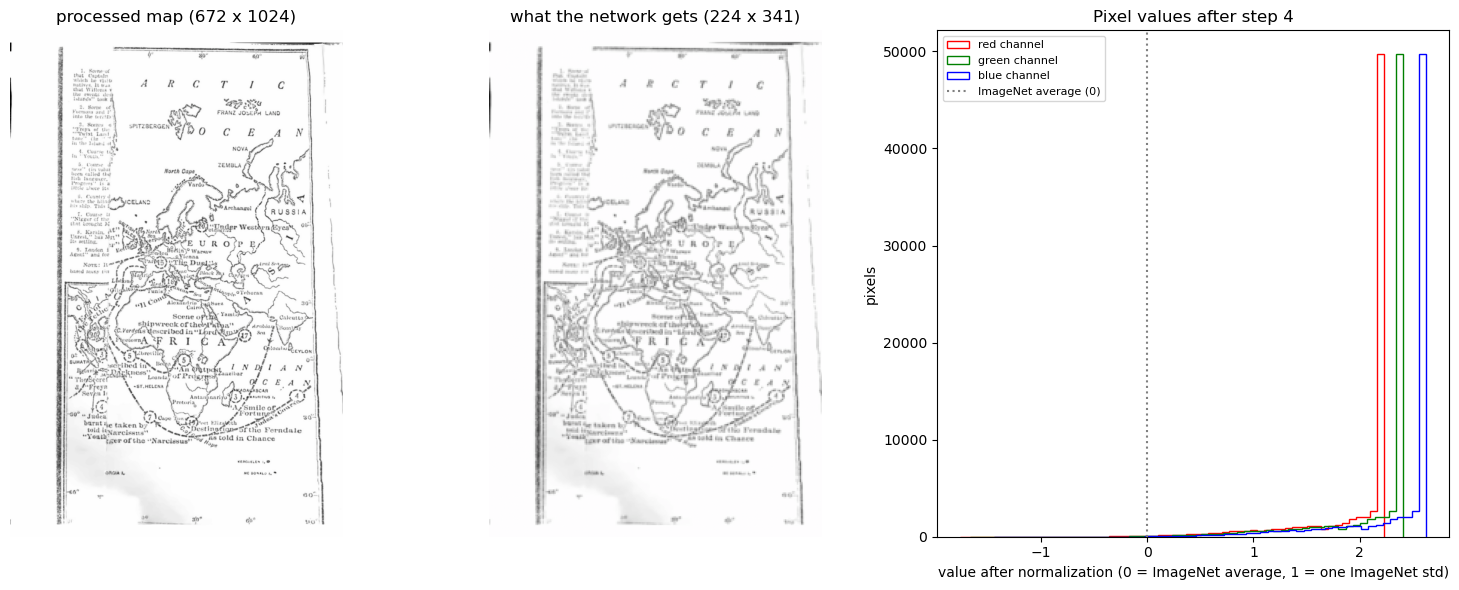

In [7]:
# One train map, before and after preparing it
rng = np.random.default_rng(SEED)
example_path = PROC / splits["train"]["path"][rng.choice(np.where(is_original)[0])]
example = prepare_image(example_path)
with Image.open(example_path) as img:
    original = np.asarray(img.convert("RGB"))

print("processed map:", original.shape, "(height, width, channels), values", original.min(), "to", original.max())
print("network input:", tuple(example.shape), "(channels, height, width), values",
      round(example.min().item(), 2), "to", round(example.max().item(), 2))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
axes[0].imshow(original)
axes[0].set_title(f"processed map ({original.shape[1]} x {original.shape[0]})")
axes[1].imshow(to_displayable(example))
axes[1].set_title(f"what the network gets ({EMBED_SIZE[0]} x {EMBED_SIZE[1]})")
for ax in axes[:2]:
    ax.axis("off")

for channel, color in enumerate(["red", "green", "blue"]):
    axes[2].hist(example[channel].numpy().ravel(), bins=60, histtype="step", color=color, label=f"{color} channel")
axes[2].axvline(0, color="gray", linestyle=":", label="ImageNet average (0)")
axes[2].set_xlabel("value after normalization (0 = ImageNet average, 1 = one ImageNet std)")
axes[2].set_ylabel("pixels")
axes[2].set_title("Pixel values after step 4")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the histogram.** An average ImageNet photo would spread around 0. Our maps are mostly bright paper, so most values pile up far to the right (around +1.5 to +2) with a thin tail of dark ink to the left. That is a first sign of the **domain gap**: old line drawings look nothing like the photos the network learned from. Section 6 shows what the network makes of them.

## 6. The network step by step

PyTorch always works on **batches**: a stack of images with shape (batch size, channels, height, width). For one image, `unsqueeze(0)` adds a batch dimension of size 1.

`run_stages` runs ResNet-50 one stage at a time (the same steps `extractor(images)` runs internally) and keeps each stage's output, so we can watch the picture shrink while the number of channels grows. The last line checks that it gives the same embedding as `extractor`.

`torch.no_grad()` tells PyTorch not to keep the bookkeeping it would need for training (gradients). We only run images forward, so this saves memory and time.

In [8]:
def run_stages(images):
    """Run ResNet-50 one stage at a time and keep every stage's output. Same math as extractor(images)."""
    outputs = {"input": images}
    x = extractor.maxpool(extractor.relu(extractor.bn1(extractor.conv1(images))))
    outputs["stem (conv1 + max pool)"] = x
    for name in ["layer1", "layer2", "layer3", "layer4"]:
        x = getattr(extractor, name)(x)
        outputs[name] = x
    outputs["avgpool = embedding"] = torch.flatten(extractor.avgpool(x), 1)  # average over height and width
    return outputs


batch = example.unsqueeze(0).to(DEVICE)   # a batch of 1 image
with torch.no_grad():
    stages = run_stages(batch)
    embedding = extractor(batch)

print("run_stages gives the same embedding as extractor:",
      torch.allclose(stages["avgpool = embedding"], embedding, atol=1e-4))
pd.DataFrame([{"stage": name,
               "output shape (batch, channels, height, width)": tuple(out.shape),
               "numbers per image": f"{out[0].numel():,}"}
              for name, out in stages.items()])

run_stages gives the same embedding as extractor: True


,stage,"output shape (batch, channels, height, width)",numbers per image
0,input,"(1, 3, 341, 224)","229,152"
1,stem (conv1 + max pool),"(1, 64, 86, 56)","308,224"
2,layer1,"(1, 256, 86, 56)","1,232,896"
3,layer2,"(1, 512, 43, 28)","616,448"
4,layer3,"(1, 1024, 22, 14)","315,392"
5,layer4,"(1, 2048, 11, 7)","157,696"
6,avgpool = embedding,"(1, 2048)","2,048"


The 224 x 341 input ends up as a grid of about 7 x 11 spots after layer4, each described by 2,048 numbers. Every spot "sees" a large patch of the page, so this grid is coarse. The average pool then averages each channel over the grid. That throws away *where* things are and keeps *how much* of each pattern the page contains, which suits a question like "is this a floor plan or a continent?" better than "where is the compass rose?".

### What does the full network think a map is?

Before using the embedding as our feature, we can put the removed last layer back on (`imagenet_head`) and ask the full network for its ImageNet guesses: embedding -> 1,000 scores -> softmax -> probabilities. This is only a demonstration; the classifier never uses these guesses.

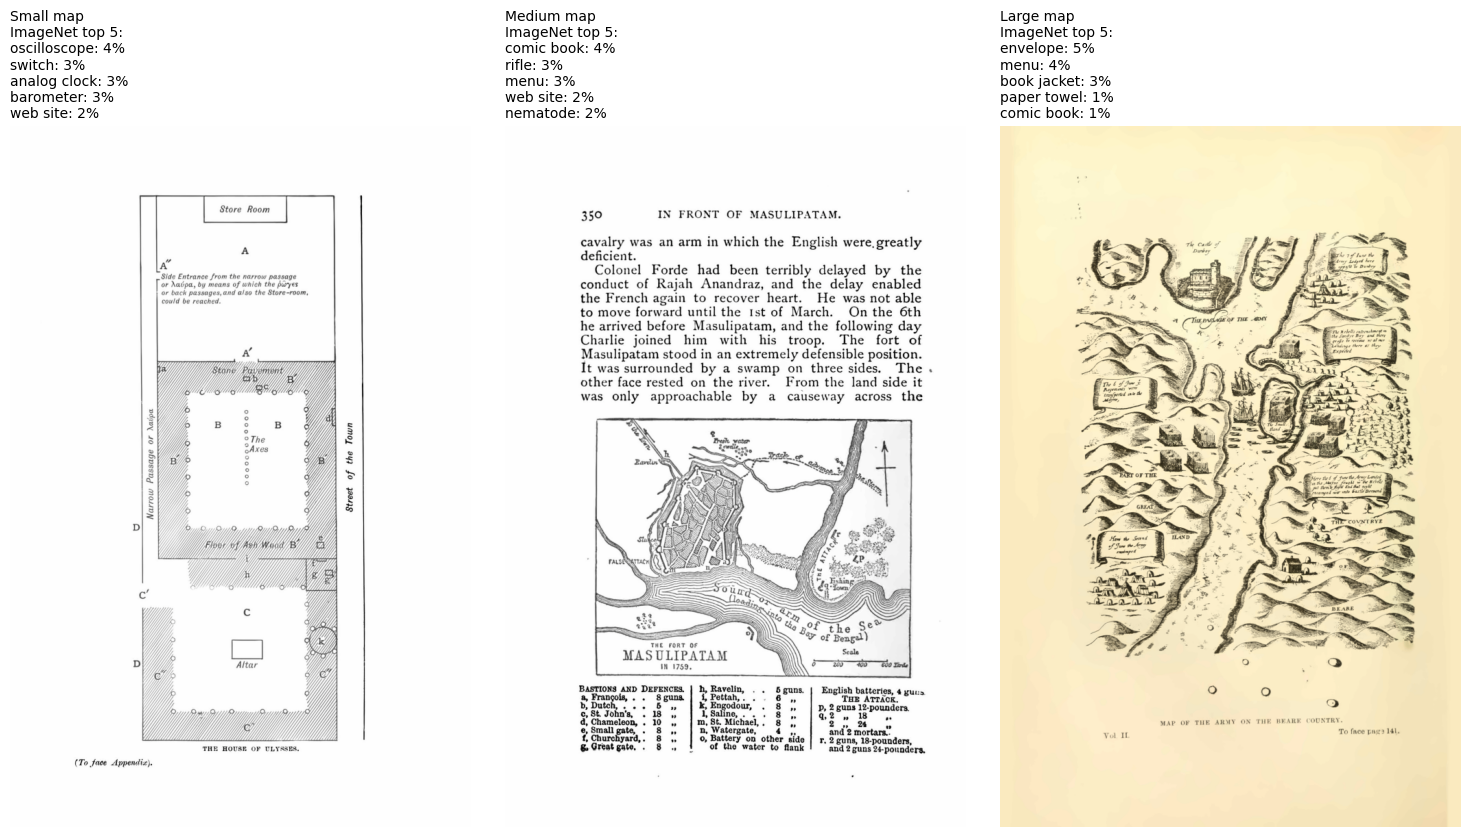

In [9]:
# One random train map per class (reused for the pictures in section 8)
rng = np.random.default_rng(SEED)
example_rows = {}
for class_id in range(3):
    example_rows[class_id] = rng.choice(np.where(is_original & (y["train"] == class_id))[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for class_id, ax in enumerate(axes):
    path = PROC / splits["train"].loc[example_rows[class_id], "path"]
    with torch.no_grad():
        emb = extractor(prepare_image(path).unsqueeze(0).to(DEVICE)).cpu()
        probabilities = torch.softmax(imagenet_head(emb), dim=1)[0]   # 1,000 probabilities that add up to 1
    top = torch.topk(probabilities, 5)
    guesses = [f"{IMAGENET_CATEGORIES[i]}: {p:.0%}" for p, i in zip(top.values.tolist(), top.indices.tolist())]

    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{CLASS_NAMES[class_id]} map\nImageNet top 5:\n" + "\n".join(guesses), fontsize=10, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Reading this.** ImageNet has no "map" category, so the network answers with the closest things it knows. For scanned book pages, expect categories like "crossword puzzle", "maze", "envelope", "book jacket" or "menu": objects made of lines, grids, text and paper. The guesses are wrong, but they hint at what the embedding describes - how grid-like, maze-like or text-heavy a page looks. Our own logistic regression gets to learn which of those qualities line up with Small, Medium and Large.

## 7. Embeddings for every image

For each split, `embed_paths` prepares the images, sends them through the frozen network `BATCH_SIZE` at a time, and stacks the results into an array with one row per image and 2,048 columns. Batches are much faster than one image at a time, especially on a GPU.

The result is saved to `data/features/resnet50_<split>.npz`, together with the list of image paths and the settings. On the next run, the saved file is used only if the manifest's rows and the settings still match exactly. So after re-running `1-preprocessing` or `2-augment` (or changing `EMBED_WIDTH` or `WEIGHTS`), the embeddings are recomputed automatically. Set `RECOMPUTE_EMBEDDINGS = True` to force it.

Other notebooks can load the same embeddings, in the same row order as the manifest:
```python
saved = np.load(ROOT / "data" / "features" / "resnet50_train.npz")
X_train = saved["X"]          # (n_train_images, 2048)
paths = saved["paths"]        # matches manifest rows where split == "train", in order
```

In [10]:
CACHE_INFO = {"weights": str(WEIGHTS), "embed_size": list(EMBED_SIZE), "layer": "avgpool (penultimate)"}


def embed_paths(paths, desc):
    """Run every image through the frozen network, BATCH_SIZE at a time. Returns (n_images x 2048 array, seconds)."""
    chunks = []
    start_time = time.perf_counter()
    for start in range(0, len(paths), BATCH_SIZE):
        batch_paths = paths[start : start + BATCH_SIZE]
        batch = torch.stack([prepare_image(PROC / p) for p in batch_paths]).to(DEVICE)
        with torch.no_grad():
            chunks.append(extractor(batch).cpu().numpy())
        done = start + len(batch_paths)
        print(f"\r{desc}: {done}/{len(paths)} images ({time.perf_counter() - start_time:.0f} s)", end="")
    print()
    return np.concatenate(chunks).astype(np.float32), time.perf_counter() - start_time


def cache_file(split_name):
    return FEATURE_DIR / f"resnet50_{split_name}.npz"


def load_saved(split_name, paths):
    """The saved embeddings for this split, or None if there are none or they're out of date."""
    file = cache_file(split_name)
    if RECOMPUTE_EMBEDDINGS or not file.exists():
        return None
    saved = np.load(file, allow_pickle=False)
    same_rows = saved["paths"].tolist() == list(paths)
    same_settings = json.loads(str(saved["info"])) == CACHE_INFO
    if same_rows and same_settings:
        return saved["X"], float(saved["seconds"]), str(saved["device"])
    print(f"{file.name} is out of date (the manifest or the settings changed) - recomputing")
    return None

In [11]:
X = {}               # X[split] = embeddings, one row per manifest row of that split
extract_seconds = {} # how long the network took per split (on extract_device)
extract_device = {}
for split_name in ["train", "val", "test"]:
    paths = splits[split_name]["path"].tolist()
    saved = load_saved(split_name, paths)
    if saved is not None:
        X[split_name], extract_seconds[split_name], extract_device[split_name] = saved
        print(f"{split_name}: loaded {len(paths)} saved embeddings from {cache_file(split_name).name}")
    else:
        X[split_name], extract_seconds[split_name] = embed_paths(paths, split_name)
        extract_device[split_name] = DEVICE
        np.savez(cache_file(split_name), X=X[split_name], paths=np.array(paths), info=json.dumps(CACHE_INFO),
                 seconds=extract_seconds[split_name], device=DEVICE)
    print(f"   {split_name} embeddings: {X[split_name].shape[0]} images x {X[split_name].shape[1]} numbers")

assert X["train"].shape[1] == EMBED_DIM

train: 3070/3070 images (49 s)
   train embeddings: 3070 images x 2048 numbers
val: 292/292 images (4 s)
   val embeddings: 292 images x 2048 numbers
test: 290/290 images (4 s)
   test embeddings: 290 images x 2048 numbers


#### Timing the embedding (for the efficiency section)

The bulk run above may have used a GPU, while the features in `3-simple_model` were timed on one CPU core. To compare costs "assuming equal computational power", we time the network again on the **CPU, with one thread, one image at a time**, on the same number of training images (`N_TIMING_IMAGES`). The timer is split into loading + preparing the image and running the network, to show which part costs more. One untimed warm-up run comes first, because the first call is always slow.

In [12]:
timing_paths = splits["train"]["path"].tolist()[:N_TIMING_IMAGES]
threads_before = torch.get_num_threads()
extractor.to("cpu")
torch.set_num_threads(TIMING_CPU_THREADS)
try:
    prep_seconds = 0.0
    network_seconds = 0.0
    with torch.no_grad():
        extractor(prepare_image(PROC / timing_paths[0]).unsqueeze(0))   # warm-up, not timed
        for path in timing_paths:
            t = time.perf_counter()
            one_image = prepare_image(PROC / path).unsqueeze(0)
            prep_seconds += time.perf_counter() - t

            t = time.perf_counter()
            extractor(one_image)
            network_seconds += time.perf_counter() - t
finally:
    torch.set_num_threads(threads_before)   # put things back even if something above fails
    extractor.to(DEVICE)

prep_ms = 1000 * prep_seconds / len(timing_paths)
network_ms = 1000 * network_seconds / len(timing_paths)
embed_ms_per_image = prep_ms + network_ms
n_embedded = sum(len(splits[s]) for s in splits)
bulk_ms_per_image = 1000 * sum(extract_seconds.values()) / n_embedded

print(f"CPU, {TIMING_CPU_THREADS} thread, 1 image at a time: {embed_ms_per_image:.1f} ms per image "
      f"(load + prepare {prep_ms:.1f} ms, network {network_ms:.1f} ms)")
print(f"Bulk run above on {extract_device['train']}, batches of {BATCH_SIZE}: {bulk_ms_per_image:.1f} ms per image")

CPU, 1 thread, 1 image at a time: 143.9 ms per image (load + prepare 10.4 ms, network 133.5 ms)
Bulk run above on cuda, batches of 32: 15.7 ms per image


## 8. Look at the embeddings

Everything in this section uses **one row per train map** (`variant == "original"`), so augmented copies and rescans don't count twice - the same rule `3-simple_model` used for its plots. Val and test are not touched.

### 8a. Three example maps

For the example map of each class from section 6:
- **Left:** what the network gets.
- **Middle:** where the network responds. layer4's output is a coarse grid (about 7 x 11) with 2,048 numbers per spot; averaging those 2,048 numbers gives one "how much is going on here" value per spot, drawn over the map (brighter = stronger). This is a rough picture of where the patterns the network cares about are, not an exact explanation of the embedding.
- **Right:** the embedding itself, the 2,048 numbers laid out as a 32 x 64 grid. ResNet-50's last layers use ReLU, which turns negatives into 0, so the embedding has no negative numbers and many near-zero ones. Each number is one channel's average over the page: "how much of pattern #k is on this page". Different maps light up different channels.

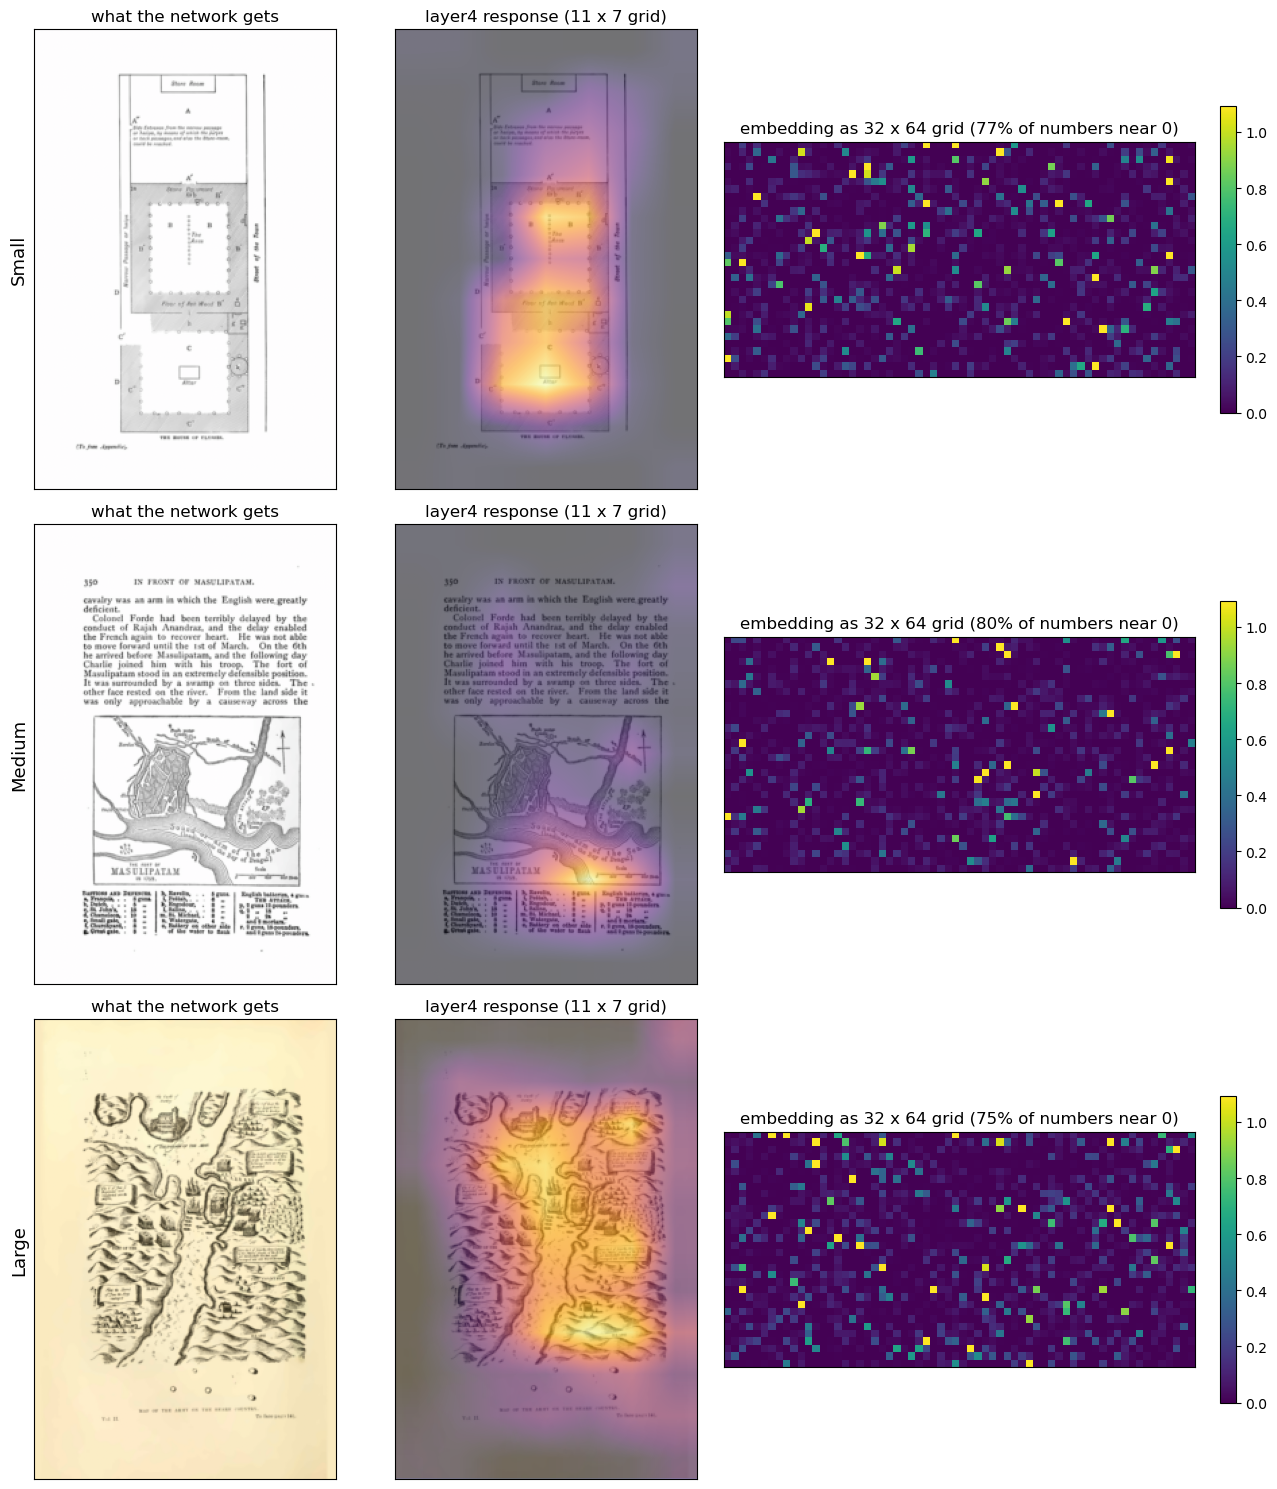

In [13]:
embedding_vmax = np.percentile(X["train"], 99)   # same color scale for all three embeddings

fig, axes = plt.subplots(3, 3, figsize=(13, 15), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for class_id in range(3):
    path = PROC / splits["train"].loc[example_rows[class_id], "path"]
    image_tensor = prepare_image(path)
    with torch.no_grad():
        stages = run_stages(image_tensor.unsqueeze(0).to(DEVICE))
    layer4 = stages["layer4"][0].cpu().numpy()            # (2048, grid height, grid width)
    emb = stages["avgpool = embedding"][0].cpu().numpy()  # (2048,)

    shown = to_displayable(image_tensor)
    height, width = shown.shape[:2]

    axes[class_id, 0].imshow(shown)
    axes[class_id, 0].set_title("what the network gets")

    axes[class_id, 1].imshow(shown)
    axes[class_id, 1].imshow(layer4.mean(axis=0), cmap="inferno", alpha=0.55,
                             extent=(0, width, height, 0), interpolation="bilinear")
    axes[class_id, 1].set_title(f"layer4 response ({layer4.shape[1]} x {layer4.shape[2]} grid)")

    picture = axes[class_id, 2].imshow(emb.reshape(32, 64), cmap="viridis", vmin=0, vmax=embedding_vmax)
    axes[class_id, 2].set_title(f"embedding as 32 x 64 grid ({(emb < 0.05).mean():.0%} of numbers near 0)")
    fig.colorbar(picture, ax=axes[class_id, 2], fraction=0.03)

    for ax in axes[class_id]:
        ax.set_xticks([])
        ax.set_yticks([])
    axes[class_id, 0].set_ylabel(CLASS_NAMES[class_id], fontsize=13)
plt.tight_layout()
plt.show()

### 8b. ImageNet's guesses across all train maps

Section 6 showed the full network's guesses for three maps. Because the removed last layer is a simple linear layer, we can apply it to every saved embedding at almost no cost. The table shows the five most common top-1 ImageNet guesses for each class, with the share of that class's maps that got each guess. If the classes get different guesses, the embedding already "sees" a difference between them.

In [14]:
X_train_maps = X["train"][is_original]   # one row per train map

with torch.no_grad():
    top1 = imagenet_head(torch.from_numpy(X_train_maps)).argmax(dim=1).numpy()

guess_rows = {}
for class_id in range(3):
    names = pd.Series([IMAGENET_CATEGORIES[i] for i in top1[y_train_maps == class_id]])
    shares = names.value_counts(normalize=True).head(5)
    guesses = [f"{name} ({share:.0%})" for name, share in shares.items()]
    guesses += [""] * (5 - len(guesses))   # a class may get fewer than 5 different guesses
    guess_rows[f"{CLASS_NAMES[class_id]} (n={len(names)})"] = guesses

pd.DataFrame(guess_rows, index=[f"#{k}" for k in range(1, 6)]).T

,#1,#2,#3,#4,#5
Small (n=118),envelope (25%),crossword puzzle (12%),menu (12%),slide rule (8%),web site (7%)
Medium (n=248),envelope (22%),book jacket (21%),web site (16%),comic book (8%),menu (8%)
Large (n=992),envelope (29%),book jacket (17%),web site (15%),menu (10%),nematode (5%)


### 8c. Which embedding numbers differ most between the classes?

For each of the 2,048 numbers separately, the **ANOVA F statistic** (`f_classif`) compares how far apart the three class averages are with how spread out each class is. A large F means the classes' averages differ by much more than the noise within each class. Left: how F is distributed over all 2,048 numbers. Right: the three numbers with the largest F.

This looks at one number at a time. Logistic regression combines all of them, so a feature set can work well even if no single number separates the classes on its own.

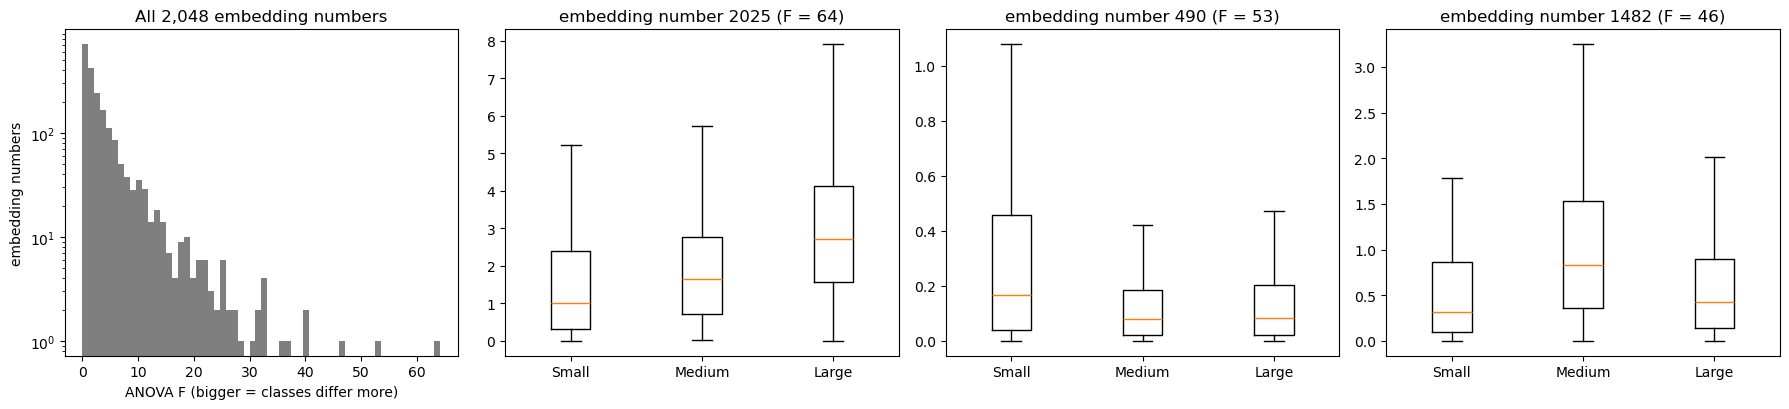

279 of 2048 embedding numbers differ between the classes at p < 0.001 (train maps; many tests at once, so read this loosely)


In [15]:
F, p_values = f_classif(X_train_maps, y_train_maps)
F = np.nan_to_num(F)   # a number that is 0 for every map gives F = NaN
top_dims = np.argsort(F)[::-1][:3]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].hist(F, bins=60, color="tab:gray")
axes[0].set_yscale("log")
axes[0].set_xlabel("ANOVA F (bigger = classes differ more)")
axes[0].set_ylabel("embedding numbers")
axes[0].set_title("All 2,048 embedding numbers")

for ax, dim in zip(axes[1:], top_dims):
    ax.boxplot([X_train_maps[y_train_maps == c, dim] for c in range(3)], showfliers=False)
    ax.set_xticks([1, 2, 3], CLASS_NAMES)
    ax.set_title(f"embedding number {dim} (F = {F[dim]:.0f})")
plt.tight_layout()
plt.show()

print(f"{(p_values < 0.001).sum()} of {EMBED_DIM} embedding numbers differ between the classes at p < 0.001 "
      f"(train maps; many tests at once, so read this loosely)")

### 8d. PCA: how much variation is there, and in how many directions?

**PCA** (principal component analysis) finds the directions in the 2,048-number space along which the maps vary the most. The first component is the single direction with the most spread, the second is the next-most at right angles to the first, and so on. The **explained variance** of a component is the share of all the variation it captures.

We standardize first (mean 0, std 1 per number, the same step the classifier uses) and fit PCA on the train maps only.
- **Left:** cumulative explained variance. If a few components explain most of the variation, the 2,048 numbers are highly redundant and a small PCA should lose little. The dots mark the PCA sizes the search in section 9 tries.
- **Right:** every train map placed by its first two components, colored by class. PCA doesn't know the labels, so any separation here is "free".

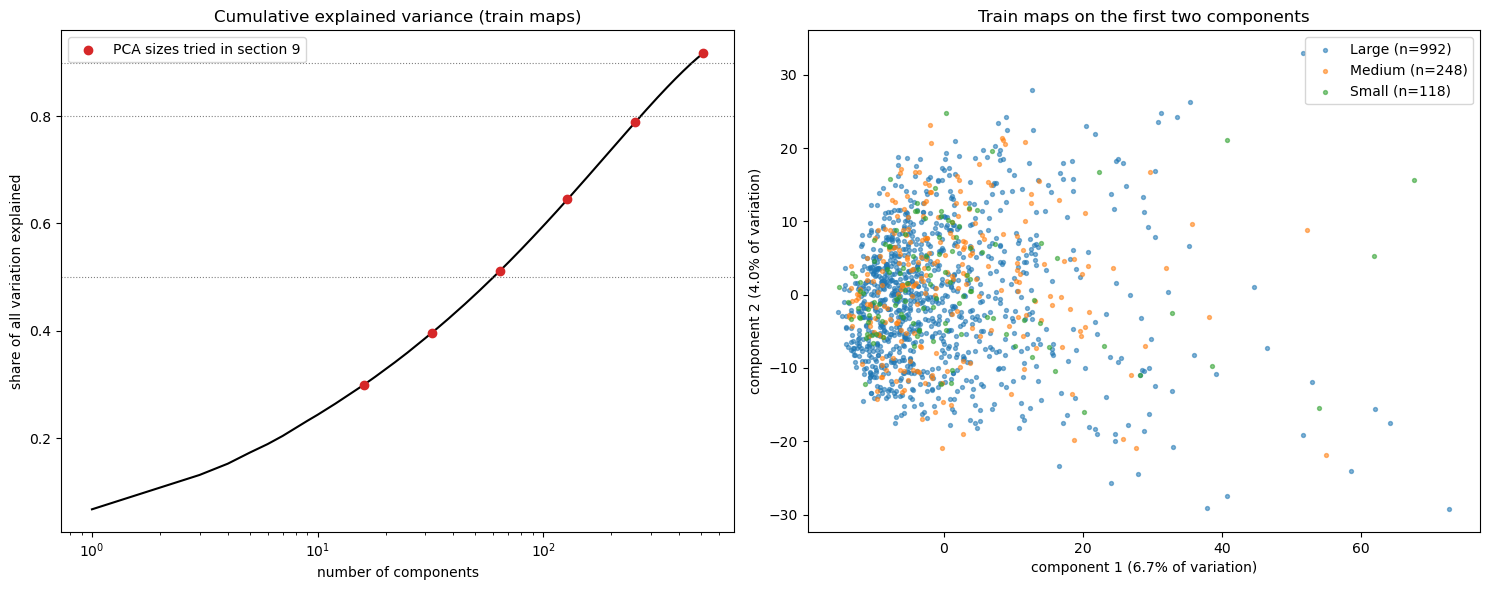

61 components explain 50% of the variation
270 components explain 80% of the variation
458 components explain 90% of the variation


In [16]:
viz_scaler = StandardScaler().fit(X_train_maps)
X_train_maps_scaled = viz_scaler.transform(X_train_maps)
viz_pca = PCA(n_components=min(512, len(X_train_maps) - 1), random_state=SEED).fit(X_train_maps_scaled)
Z = viz_pca.transform(X_train_maps_scaled)              # each map's coordinates along the components
cumulative = np.cumsum(viz_pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
components = np.arange(1, len(cumulative) + 1)
axes[0].plot(components, cumulative, color="black")
marked = [d for d in PCA_DIMS if d <= len(cumulative)]
if marked:
    axes[0].scatter(marked, cumulative[np.array(marked, dtype=int) - 1], color="tab:red", zorder=3,
                    label="PCA sizes tried in section 9")
for level in [0.5, 0.8, 0.9]:
    axes[0].axhline(level, color="gray", linestyle=":", linewidth=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("number of components")
axes[0].set_ylabel("share of all variation explained")
axes[0].set_title("Cumulative explained variance (train maps)")
axes[0].legend()

for class_id in [2, 1, 0]:   # Large first, so the rarer classes are drawn on top
    rows = y_train_maps == class_id
    axes[1].scatter(Z[rows, 0], Z[rows, 1], s=8, alpha=0.55, color=CLASS_COLORS[class_id],
                    label=f"{CLASS_NAMES[class_id]} (n={rows.sum()})")
axes[1].set_xlabel(f"component 1 ({viz_pca.explained_variance_ratio_[0]:.1%} of variation)")
axes[1].set_ylabel(f"component 2 ({viz_pca.explained_variance_ratio_[1]:.1%} of variation)")
axes[1].set_title("Train maps on the first two components")
axes[1].legend()
plt.tight_layout()
plt.show()

for level in [0.5, 0.8, 0.9]:
    if cumulative[-1] >= level:
        print(f"{np.searchsorted(cumulative, level) + 1} components explain {level:.0%} of the variation")
    else:
        print(f"{len(cumulative)} components explain {cumulative[-1]:.0%} of the variation (less than {level:.0%})")

### 8e. t-SNE: who are each map's neighbors?

**t-SNE** squeezes the maps into 2 dimensions in a way that keeps maps that are close in the embedding close in the picture. Unlike PCA it bends and stretches space freely, so it can show clusters that PCA's two straight directions miss. Things to keep in mind:
- Only **neighborhoods** mean something. The size of a cluster and the distance between two clusters don't.
- `perplexity` is roughly how many neighbors each map pays attention to (30 is the usual default).
- It runs on the first 50 PCA components from 8d, a standard step that removes noise and makes it faster.

Under the picture, a number check of the same idea: for each train map, the share of its 10 nearest neighbors (in the same 50-component space) that have the same class. Compare that with the class's share of all maps, which is what you'd get if neighbors were random.

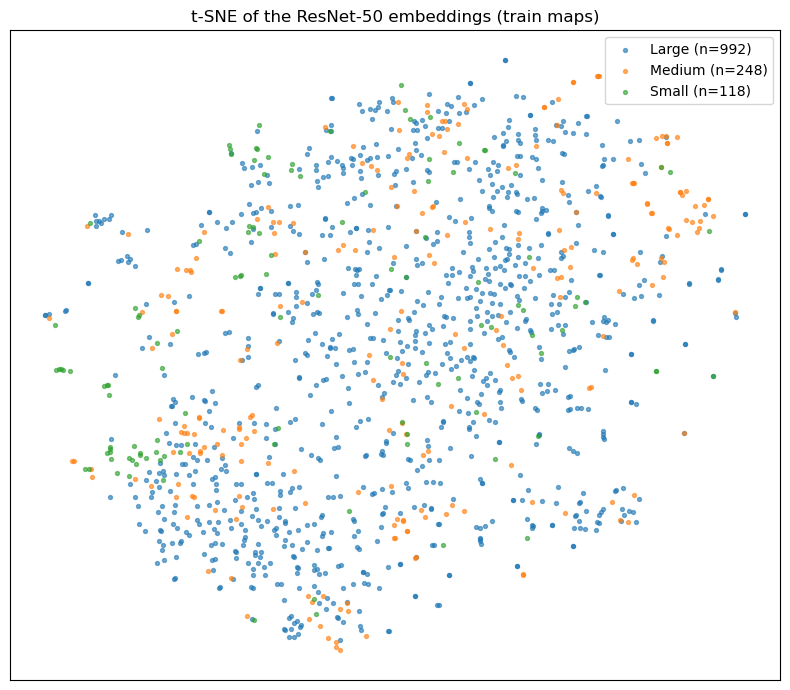

,share of 10 nearest neighbors with the same class,if neighbors were random (class share)
Small,0.262,0.087
Medium,0.333,0.183
Large,0.795,0.730


In [17]:
Z50 = Z[:, :50]
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED)
T2 = tsne.fit_transform(Z50)

fig, ax = plt.subplots(figsize=(8, 7))
for class_id in [2, 1, 0]:
    rows = y_train_maps == class_id
    ax.scatter(T2[rows, 0], T2[rows, 1], s=8, alpha=0.6, color=CLASS_COLORS[class_id],
               label=f"{CLASS_NAMES[class_id]} (n={rows.sum()})")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("t-SNE of the ResNet-50 embeddings (train maps)")
ax.legend()
plt.tight_layout()
plt.show()

# Neighbor check: 11 neighbors because each map's nearest neighbor is itself
neighbors = NearestNeighbors(n_neighbors=11).fit(Z50).kneighbors(Z50, return_distance=False)[:, 1:]
same_class = (y_train_maps[neighbors] == y_train_maps[:, None]).mean(axis=1)
pd.DataFrame({"share of 10 nearest neighbors with the same class": [same_class[y_train_maps == c].mean() for c in range(3)],
              "if neighbors were random (class share)": [np.mean(y_train_maps == c) for c in range(3)]},
             index=CLASS_NAMES).round(3)

**How to read section 8.** If Small, Medium and Large maps sit in different regions of the PCA and t-SNE pictures, and their neighbors share their class much more often than chance, a linear classifier on these embeddings has something to work with. Overlap is expected: Large is most of the data and covers many drawing styles, and a dense estate plan can look a lot like a small town plan. Compare with section 5 of `3-simple_model`, where the class averages of the simple features looked nearly the same.

## 9. Tuning on the validation set

**The model** is the same multinomial logistic regression as `3-simple_model` (one weight per input number for each class, then softmax), with one new step in front of it:

embedding (2,048) -> **standardize** -> **PCA** to `n` components (or none) -> logistic regression

**What is tuned:**
- **PCA size** (`PCA_DIMS`): 16, 32, 64, 128, 256 or 512 components, or 2,048 = no PCA. We have about 3,000 training rows; with all 2,048 numbers the regression has over 6,000 weights, which is a lot of room to memorize the training rows (including near-copies from augmentation). PCA keeps only the directions with the most variation. It does not look at the labels, so it might throw away a small direction that matters for Small - which is why the size is tuned rather than fixed.
- **Class weighting:** none or `balanced`, as in `3-simple_model`.
- **C:** the same 13 values. Smaller C = stronger penalty on large weights = simpler model.

That is 7 x 2 x 13 = 182 settings. Each one: fit on train, score macro-F1 on val. The scaler and PCA are fit on **train only**, once per PCA size, and reused for every C and weighting (the result is the same as refitting them, just faster). The test set is not used in this section.

**Choosing a setting without overfitting the validation set.** With 182 settings and only 292 val maps (26 of them Small), the setting with the single highest val score partly won by luck. To see how much luck is involved, we score every setting on the same 200 **bootstrap resamples** of the val set: each resample draws 292 val maps at random, with replacement, so some maps count twice and some not at all. The spread of a setting's score across the resamples is its **standard error** (SE) - how much its val score would move with a different draw of val maps.

Then the **one-standard-error rule** (from Hastie, Tibshirani and Friedman, *The Elements of Statistical Learning*, section 7.10): among all settings whose val macro-F1 is within one SE of the best one, take the **simplest** - fewest PCA components first, then smallest C. Those settings are statistically tied with the winner, and the simplest of them is the least likely to have fit quirks of the val set. Set `SELECTION_RULE = "best"` to pick the plain highest val score instead, as `3-simple_model` does; both picks are printed either way.

`macro_f1_fast` computes the same number as sklearn's macro-F1 (the next cell checks this), but fast enough to run 182 x 200 times.

In [18]:
def macro_f1_fast(y_true, y_pred):
    """Macro-F1 for labels 0, 1, 2. Same result as f1_score(..., average="macro"), but much faster."""
    counts = np.bincount(3 * y_true + y_pred, minlength=9).reshape(3, 3)  # confusion matrix: rows = true, cols = predicted
    true_pos = np.diag(counts)
    false_pos = counts.sum(axis=0) - true_pos
    false_neg = counts.sum(axis=1) - true_pos
    denominator = 2 * true_pos + false_pos + false_neg
    f1_per_class = np.divide(2 * true_pos, denominator, out=np.zeros(3), where=denominator > 0)
    return f1_per_class.mean()


check_pred = np.random.default_rng(0).integers(0, 3, len(y["val"]))
assert np.isclose(macro_f1_fast(y["val"], check_pred),
                  f1_score(y["val"], check_pred, labels=[0, 1, 2], average="macro", zero_division=0))

# The same 200 resamples of the val maps are used for every setting, so the settings are compared fairly
n_val = len(y["val"])
val_resamples = np.random.default_rng(SEED).integers(0, n_val, size=(N_VAL_BOOTSTRAP, n_val))

In [19]:
search_rows = []
search_start = time.perf_counter()

scaler = StandardScaler().fit(X["train"])   # fit on train only
train_scaled = scaler.transform(X["train"])
val_scaled = scaler.transform(X["val"])

for n_dims in PCA_DIMS:
    # PCA, fit on train only (none for n_dims = 2,048)
    t = time.perf_counter()
    if n_dims < EMBED_DIM:
        pca = PCA(n_components=n_dims, random_state=SEED).fit(train_scaled)
        train_in = pca.transform(train_scaled)
        val_in = pca.transform(val_scaled)
    else:
        train_in, val_in = train_scaled, val_scaled
    pca_seconds = time.perf_counter() - t

    for class_weight in CLASS_WEIGHTS:
        weighting = "balanced" if class_weight == "balanced" else "none"
        for C in C_GRID:
            logreg = LogisticRegression(C=C, class_weight=class_weight, max_iter=MAX_ITER, random_state=SEED)
            t = time.perf_counter()
            logreg.fit(train_in, y["train"])
            fit_seconds = time.perf_counter() - t + pca_seconds   # PCA + regression, the full fitting cost

            val_pred = logreg.predict(val_in)
            resampled_scores = [macro_f1_fast(y["val"][rows], val_pred[rows]) for rows in val_resamples]
            search_rows.append({"pca_dims": n_dims, "weighting": weighting, "C": C,
                                "train_macro_f1": macro_f1_fast(y["train"], logreg.predict(train_in)),
                                "val_macro_f1": macro_f1_fast(y["val"], val_pred),
                                "val_f1_se": np.std(resampled_scores),
                                "fit_seconds": fit_seconds})

        best_here = max(r["val_macro_f1"] for r in search_rows if r["pca_dims"] == n_dims and r["weighting"] == weighting)
        print(f"PCA {n_dims:>4} | {weighting:<8} | best val macro-F1 = {best_here:.3f}   "
              f"({time.perf_counter() - search_start:.0f} s so far)")

search = pd.DataFrame(search_rows)

PCA   16 | none     | best val macro-F1 = 0.466   (0 s so far)
PCA   16 | balanced | best val macro-F1 = 0.432   (0 s so far)
PCA   32 | none     | best val macro-F1 = 0.458   (1 s so far)
PCA   32 | balanced | best val macro-F1 = 0.418   (1 s so far)
PCA   64 | none     | best val macro-F1 = 0.473   (1 s so far)
PCA   64 | balanced | best val macro-F1 = 0.436   (1 s so far)
PCA  128 | none     | best val macro-F1 = 0.484   (2 s so far)
PCA  128 | balanced | best val macro-F1 = 0.442   (2 s so far)
PCA  256 | none     | best val macro-F1 = 0.504   (3 s so far)
PCA  256 | balanced | best val macro-F1 = 0.446   (4 s so far)
PCA  512 | none     | best val macro-F1 = 0.507   (6 s so far)
PCA  512 | balanced | best val macro-F1 = 0.494   (8 s so far)
PCA 2048 | none     | best val macro-F1 = 0.503   (11 s so far)
PCA 2048 | balanced | best val macro-F1 = 0.467   (14 s so far)


In [20]:
# The plain best setting, and the one-standard-error choice
best = search.loc[search["val_macro_f1"].idxmax()]
threshold = best["val_macro_f1"] - best["val_f1_se"]
tied_with_best = search[search["val_macro_f1"] >= threshold]
simplest = tied_with_best.sort_values(["pca_dims", "C", "val_macro_f1"], ascending=[True, True, False]).iloc[0]
chosen = simplest if SELECTION_RULE == "one_se" else best


def pca_label(n_dims):
    return "no PCA" if n_dims >= EMBED_DIM else f"PCA {int(n_dims)}"


def describe(row):
    return (f"{pca_label(row['pca_dims'])}, weighting {row['weighting']}, C = {row['C']:.1e}: "
            f"val macro-F1 {row['val_macro_f1']:.3f} (SE {row['val_f1_se']:.3f}), train {row['train_macro_f1']:.3f}")


print("Highest val score:      ", describe(best))
print(f"Within one SE of it (val macro-F1 >= {threshold:.3f}): {len(tied_with_best)} of {len(search)} settings")
print("Simplest of those:      ", describe(simplest))
print(f"\nChosen ({SELECTION_RULE}):", describe(chosen))
print(f"Random guessing on val: {chance_val_f1:.3f}   Majority class on val: {majority_val_f1:.3f}")

# The 10 best settings by val score
(search.sort_values("val_macro_f1", ascending=False).head(10)
       .assign(C=lambda d: d["C"].map("{:.1e}".format)).round(3).reset_index(drop=True))

Highest val score:       PCA 512, weighting none, C = 1.0e+02: val macro-F1 0.507 (SE 0.035), train 0.966
Within one SE of it (val macro-F1 >= 0.471): 27 of 182 settings
Simplest of those:       PCA 64, weighting none, C = 1.0e-04: val macro-F1 0.473 (SE 0.035), train 0.634

Chosen (one_se): PCA 64, weighting none, C = 1.0e-04: val macro-F1 0.473 (SE 0.035), train 0.634
Random guessing on val: 0.332   Majority class on val: 0.281


,pca_dims,weighting,C,train_macro_f1,val_macro_f1,val_f1_se,fit_seconds
0,512,none,1.0e+02,0.966,0.507,0.035,1.073
1,256,none,2.2e-03,0.802,0.504,0.038,0.216
2,2048,none,4.6e-04,0.850,0.503,0.036,0.155
3,512,none,4.6e-04,0.808,0.495,0.034,0.445
4,512,balanced,1.0e+02,0.966,0.494,0.035,0.939
5,256,none,4.6e-04,0.762,0.493,0.037,0.213
6,512,none,2.2e+01,0.966,0.493,0.035,0.955
7,512,balanced,2.2e+01,0.967,0.493,0.035,0.919
8,512,balanced,4.6e+00,0.965,0.492,0.035,0.755
9,256,none,1.0e-02,0.822,0.490,0.037,0.225


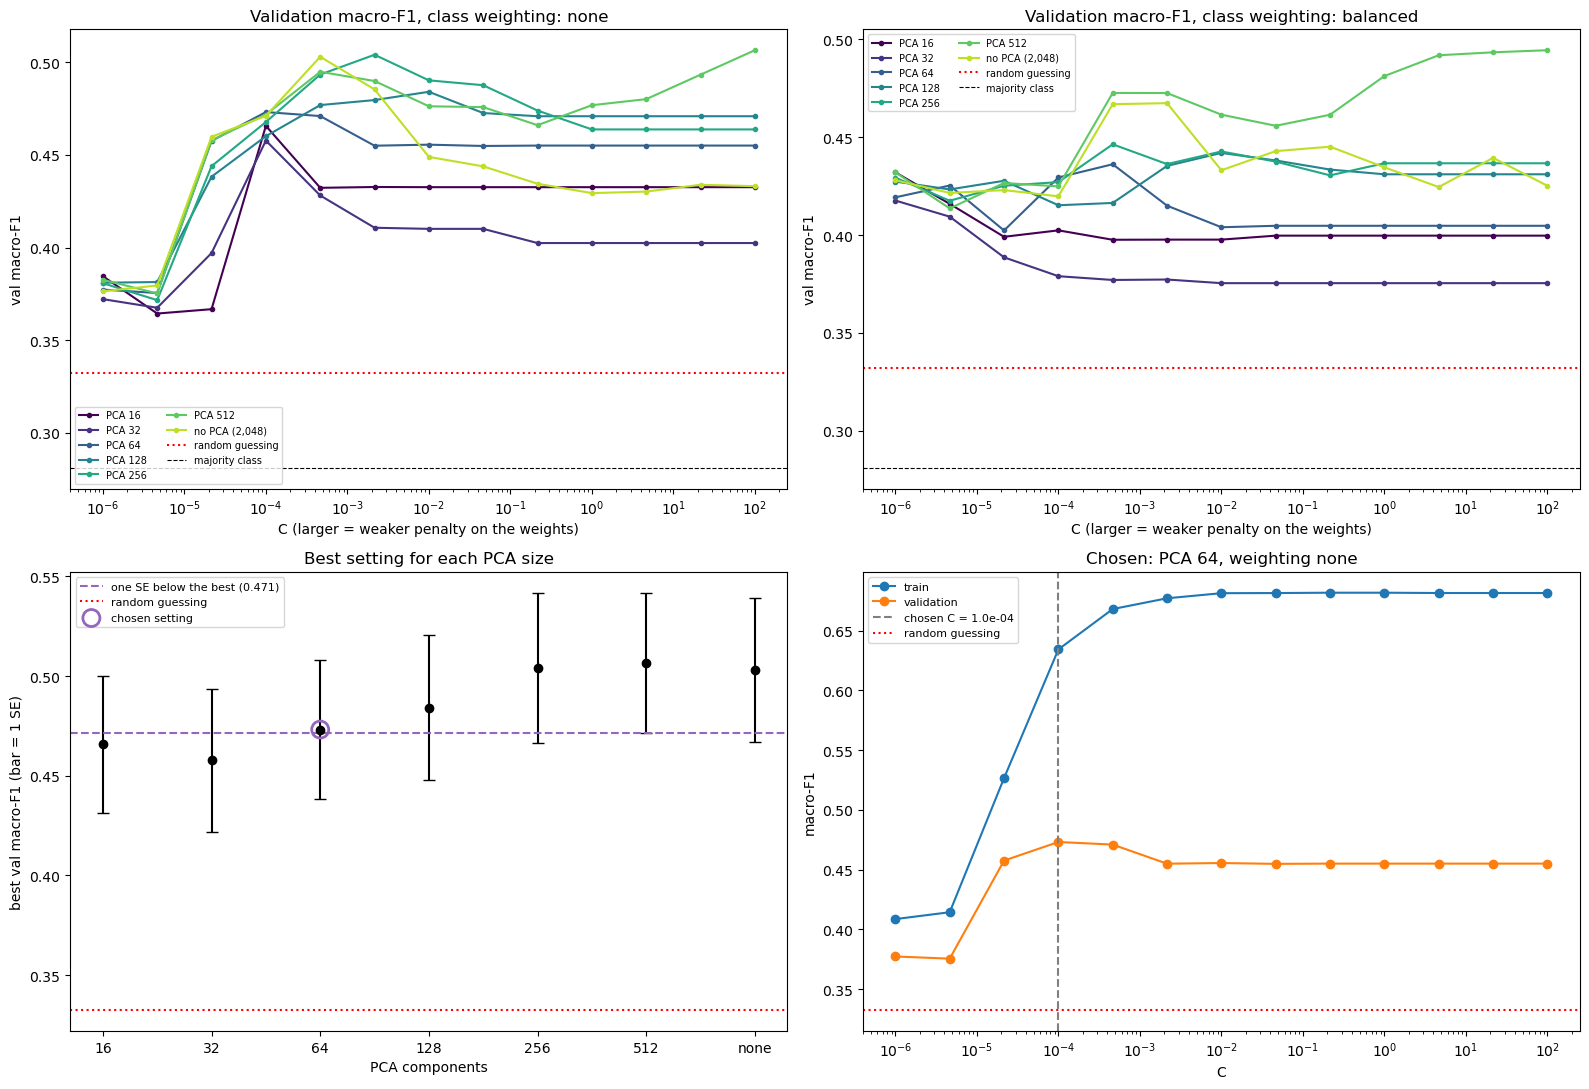

In [21]:
# Top: val macro-F1 across C for every PCA size, one panel per class weighting.
# Bottom left: the best val score of each PCA size, with its SE, and the one-SE line.
# Bottom right: train vs. val across C for the chosen PCA size and weighting (a big gap = overfitting).
fig = plt.figure(figsize=(16, 11))
size_colors = plt.cm.viridis(np.linspace(0, 0.9, len(PCA_DIMS)))

for panel, weighting in enumerate(["none", "balanced"]):
    ax = fig.add_subplot(2, 2, panel + 1)
    for n_dims, color in zip(PCA_DIMS, size_colors):
        curve = search[(search["pca_dims"] == n_dims) & (search["weighting"] == weighting)]
        label = "no PCA (2,048)" if n_dims == EMBED_DIM else f"PCA {n_dims}"
        ax.plot(curve["C"], curve["val_macro_f1"], marker="o", markersize=3, color=color, label=label)
    ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
    ax.axhline(majority_val_f1, color="black", linestyle="--", linewidth=0.8, label="majority class")
    ax.set_xscale("log")
    ax.set_xlabel("C (larger = weaker penalty on the weights)")
    ax.set_ylabel("val macro-F1")
    ax.set_title(f"Validation macro-F1, class weighting: {weighting}")
    ax.legend(fontsize=7, ncol=2)

ax = fig.add_subplot(2, 2, 3)
best_per_size = search.loc[search.groupby("pca_dims")["val_macro_f1"].idxmax()]
ax.errorbar(range(len(best_per_size)), best_per_size["val_macro_f1"], yerr=best_per_size["val_f1_se"],
            fmt="o", capsize=4, color="black")
ax.axhline(threshold, color="tab:purple", linestyle="--", label=f"one SE below the best ({threshold:.3f})")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
chosen_position = list(best_per_size["pca_dims"]).index(chosen["pca_dims"])
ax.scatter([chosen_position], [chosen["val_macro_f1"]], s=150, facecolors="none", edgecolors="tab:purple",
           linewidths=2, label="chosen setting", zorder=3)
ax.set_xticks(range(len(best_per_size)),
              ["none" if d == EMBED_DIM else str(d) for d in best_per_size["pca_dims"]])
ax.set_xlabel("PCA components")
ax.set_ylabel("best val macro-F1 (bar = 1 SE)")
ax.set_title("Best setting for each PCA size")
ax.legend(fontsize=8)

ax = fig.add_subplot(2, 2, 4)
curve = search[(search["pca_dims"] == chosen["pca_dims"]) & (search["weighting"] == chosen["weighting"])]
ax.plot(curve["C"], curve["train_macro_f1"], marker="o", label="train")
ax.plot(curve["C"], curve["val_macro_f1"], marker="o", label="validation")
ax.axvline(chosen["C"], color="gray", linestyle="--", label=f"chosen C = {chosen['C']:.1e}")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("macro-F1")
ax.set_title(f"Chosen: {pca_label(chosen['pca_dims'])}, weighting {chosen['weighting']}")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**How to read the tuning plots.**
- **Top:** each line is one PCA size. Where a line peaks shows the best C for that size. If the no-PCA line peaks at a much smaller C than the PCA lines, the model needs a strong penalty to stop it from memorizing 2,048 numbers - the job PCA does in a different way.
- **Bottom left:** if the error bars of several PCA sizes overlap, the val set can't really tell them apart, and the one-SE rule picks the smallest.
- **Bottom right:** train macro-F1 climbing toward 1 while val levels off or drops is overfitting. The chosen C should sit before that gap gets large.

## 10. Final model and test set (run once)

Refit the chosen setting on train and score test. As in `3-simple_model`, don't go back and change anything above after seeing these numbers, or the test score stops being an honest estimate.

The three steps are packed into an sklearn **Pipeline**, so `fit` runs scale -> PCA -> regression on train, and `predict` applies the same three fitted steps to new embeddings. `"passthrough"` means "skip this step" (used when the chosen setting has no PCA).

In [22]:
FINAL_DIMS = int(chosen["pca_dims"])
FINAL_WEIGHTING = chosen["weighting"]
FINAL_C = float(chosen["C"])
final_class_weight = "balanced" if FINAL_WEIGHTING == "balanced" else None

final_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=FINAL_DIMS, random_state=SEED) if FINAL_DIMS < EMBED_DIM else "passthrough"),
    ("logreg", LogisticRegression(C=FINAL_C, class_weight=final_class_weight, max_iter=MAX_ITER, random_state=SEED)),
])

t = time.perf_counter()
final_model.fit(X["train"], y["train"])
fit_seconds = time.perf_counter() - t

t = time.perf_counter()
test_pred = final_model.predict(X["test"])
predict_seconds = time.perf_counter() - t

val_pred = final_model.predict(X["val"])   # same fit as in the search, so this matches the chosen val score
val_scores = get_scores(y["val"], val_pred)
test_scores = get_scores(y["test"], test_pred)
per_class_f1 = f1_score(y["test"], test_pred, labels=[0, 1, 2], average=None, zero_division=0)

print(f"Chosen setting: {pca_label(FINAL_DIMS)}, class weighting {FINAL_WEIGHTING}, C = {FINAL_C:.2e}  ({SELECTION_RULE} rule)")
print(f"Val macro-F1:      {val_scores['macro_f1']:.3f}")
print(f"Test macro-F1:     {test_scores['macro_f1']:.3f}   (random guessing: {chance_test_f1:.3f}, majority class: {majority_test_f1:.3f})")
print(f"Test balanced acc: {test_scores['balanced_acc']:.3f}")
print(f"Test accuracy:     {test_scores['accuracy']:.3f}")
print()

# precision = of the maps it called Small, how many really were Small
# recall    = of the real Small maps, how many it found
# support   = how many test maps are in that class
print(classification_report(y["test"], test_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=3, zero_division=0))

Chosen setting: PCA 64, class weighting none, C = 1.00e-04  (one_se rule)
Val macro-F1:      0.473
Test macro-F1:     0.481   (random guessing: 0.332, majority class: 0.282)
Test balanced acc: 0.512
Test accuracy:     0.617

              precision    recall  f1-score   support

       Small      0.333     0.240     0.279        25
      Medium      0.321     0.642     0.428        53
       Large      0.837     0.656     0.735       212

    accuracy                          0.617       290
   macro avg      0.497     0.512     0.481       290
weighted avg      0.699     0.617     0.640       290



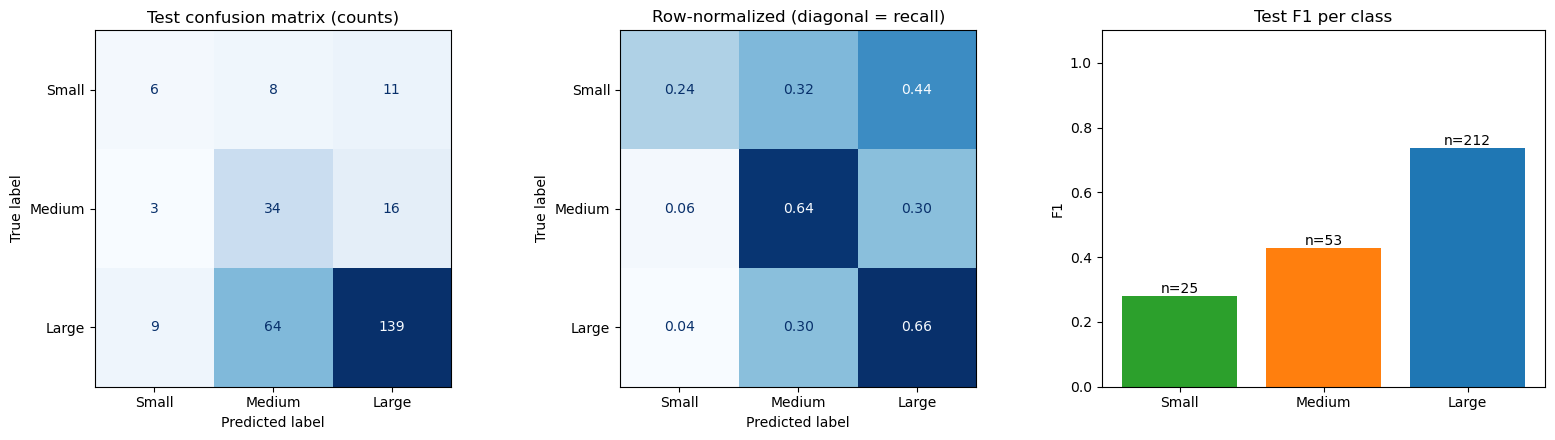

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

counts = confusion_matrix(y["test"], test_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(counts, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Test confusion matrix (counts)")

# Each row adds up to 1, so the diagonal is the recall of that class
rates = confusion_matrix(y["test"], test_pred, labels=[0, 1, 2], normalize="true")
ConfusionMatrixDisplay(rates, display_labels=CLASS_NAMES).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Row-normalized (diagonal = recall)")

class_counts = np.bincount(y["test"], minlength=3)
bars = axes[2].bar(CLASS_NAMES, per_class_f1, color=CLASS_COLORS)
for k, bar in enumerate(bars):
    axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"n={class_counts[k]}", ha="center")
axes[2].set_ylim(0, 1.1)
axes[2].set_ylabel("F1")
axes[2].set_title("Test F1 per class")

plt.tight_layout()
plt.show()

## 11. Comparison to the baselines

Same checks as `3-simple_model`:
- A **bootstrap** over the test maps puts a 95% interval on the test macro-F1 (the test set has only about 25 Small maps, so the score is noisy).
- The **share of random-guessing runs** that score at least as high as the model says how likely its edge is to be luck.
- `3-simple_model`'s result is copied from its 11/4 run (README) for reference; update it if that notebook is re-run.

Then a per-class table shows which classes any edge comes from.

In [24]:
rng = np.random.default_rng(SEED)
n_test = len(y["test"])
boot_f1 = []
for _ in range(N_BOOTSTRAP):
    rows = rng.integers(0, n_test, n_test)
    boot_f1.append(macro_f1_fast(y["test"][rows], test_pred[rows]))
model_low, model_high = np.percentile(boot_f1, [2.5, 97.5])

share_as_good = (guess_f1["test"] >= test_scores["macro_f1"]).mean()

comparison = pd.DataFrame([
    {"model": "majority_class", "test_macro_f1": majority_test_f1,
     "test_accuracy": baseline_value("majority_class", "test", "accuracy"), "95% range": "-"},
    {"model": "random_guess (mean)", "test_macro_f1": chance_test_f1,
     "test_accuracy": baseline_value("random_guess (mean)", "test", "accuracy"),
     "95% range": f"{chance_test_range[0]:.3f} - {chance_test_range[1]:.3f} (across random runs)"},
    {"model": "3-simple_model: logistic regression (combo), 11/4 run", "test_macro_f1": 0.385,
     "test_accuracy": 0.614, "95% range": "0.33 - 0.44 (bootstrap, from README)"},
    {"model": f"ResNet-50 embedding + logistic regression ({pca_label(FINAL_DIMS)}, {FINAL_WEIGHTING})",
     "test_macro_f1": test_scores["macro_f1"], "test_accuracy": test_scores["accuracy"],
     "95% range": f"{model_low:.3f} - {model_high:.3f} (bootstrap over test maps)"},
])

print(f"Test macro-F1 {test_scores['macro_f1']:.3f}: {share_as_good:.1%} of the {N_GUESS_SEEDS} "
      f"random-guessing runs score at least this high.")
print("Rough guide: over 5% = could easily be luck, 1-5% = borderline, under 1% = clearly better than guessing.")
print(f"Val macro-F1 {val_scores['macro_f1']:.3f} vs. test {test_scores['macro_f1']:.3f}: "
      f"a test score far below val would mean the setting fit the val set by luck.")
comparison.round(3)

Test macro-F1 0.481: 0.0% of the 1000 random-guessing runs score at least this high.
Rough guide: over 5% = could easily be luck, 1-5% = borderline, under 1% = clearly better than guessing.
Val macro-F1 0.473 vs. test 0.481: a test score far below val would mean the setting fit the val set by luck.


,model,test_macro_f1,test_accuracy,95% range
0,majority_class,0.282,0.731,-
1,random_guess (mean),0.332,0.574,0.279 - 0.389 (across random runs)
2,"3-simple_model: logistic regression (combo), 1...",0.385,0.614,"0.33 - 0.44 (bootstrap, from README)"
3,ResNet-50 embedding + logistic regression (PCA...,0.481,0.617,0.406 - 0.556 (bootstrap over test maps)


In [25]:
per_class = pd.DataFrame({
    "model F1": per_class_f1,
    "random guessing F1": guess_per_class["test"],
    "majority class F1": f1_score(y["test"], majority_pred["test"], labels=[0, 1, 2], average=None, zero_division=0),
    "test maps": np.bincount(y["test"], minlength=3),
}, index=CLASS_NAMES)
per_class["model minus random"] = per_class["model F1"] - per_class["random guessing F1"]
per_class.round(3)

,model F1,random guessing F1,majority class F1,test maps,model minus random
Small,0.279,0.083,0.000,25,0.196
Medium,0.428,0.183,0.000,53,0.245
Large,0.735,0.730,0.845,212,0.006


**How to read this.**
- **Did it beat guessing?** Look at the share of random runs that score as high as the model. `3-simple_model` was at about 4% (borderline). The question is whether the embedding moves the score clearly out of the guessing range, ideally with a bootstrap interval that sits above the random-guessing range.
- **Where does the edge come from?** The per-class table. Ideas for why the classes may differ:
  - **Small** (floor plans, estates) is drawn with straight walls, right angles and room grids. ImageNet networks respond strongly to grid-like man-made patterns (check whether "crossword puzzle" or "maze" show up for Small in section 8b), so Small may gain the most over the simple features, which couldn't see structure at all. It is also the rarest class (about 25 test maps), so its F1 is the noisiest.
  - **Medium** (cities, towns) has dense street networks and many labels. It can be confused with Small (an estate plan with paths and buildings looks like a town plan) and with Large (a region map crowded with towns).
  - **Large** (regions, countries, continents) is most of the data and covers the most drawing styles: coastlines, mountains, sea, decorative borders. With balanced training data the model may give up some Large maps to catch more Small and Medium ones.
- **Generalizability:** compare val and test. If test lands close to val (within about one SE), the tuning did not overfit the val set.

**Results of this run:** *(fill in after running - test macro-F1 and its interval, the share of random runs at least as good, which class gained the most over `3-simple_model`, and how close test came to val)*

## 12. Efficiency

Costs for the efficiency-vs-accuracy comparison, on the same basis as `3-simple_model` (CPU, one thread, one image at a time for the features):
- **Training cost** = embedding every training image + fitting (scaler + PCA + regression)
- **Inference cost per image** = loading, preparing and embedding one image + its share of the prediction time

The bulk run's time (on a GPU, if there is one) is shown too, as what the pipeline actually costs on the best hardware available.

The right plot shows every setting from the search: val macro-F1 against fitting time. It shows how much the classifier settings change the cost - compared with the time spent in the network.

For comparison, 3-simple_model (11/4 run): training cost 88.8 s, inference 28.9 ms per image.


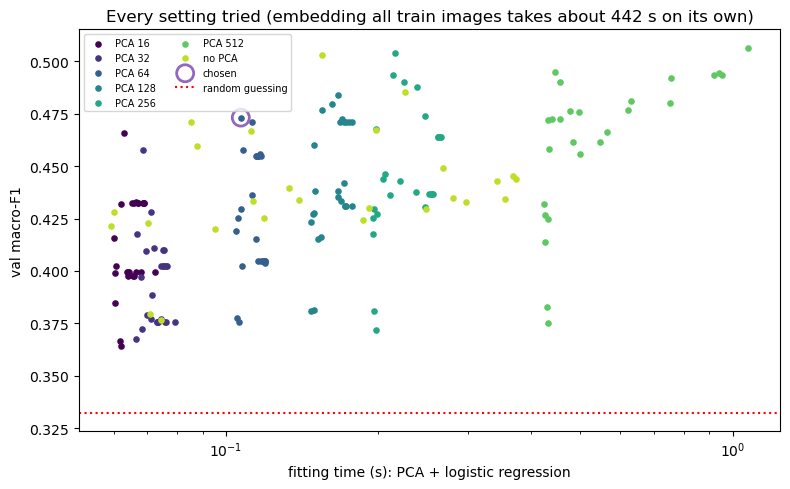

,item,value,note
0,"embed 1 image (CPU, 1 thread)",143.9 ms,"load + prepare 10.4 ms, network 133.5 ms"
1,embed 1 image (bulk run on cuda),15.7 ms,batches of 32
2,"embed all 3070 training images (CPU, 1 thread)",441.9 s,
3,fit scaler + PCA + logistic regression,0.13 s,PCA 64
4,training cost (embed train + fit),442.0 s,used in the comparison
5,inference cost per image (embed + predict),143.9 ms,used in the comparison


In [26]:
n_train = len(y["train"])
embed_train_seconds = embed_ms_per_image / 1000 * n_train
train_cost_seconds = embed_train_seconds + fit_seconds
inference_ms = embed_ms_per_image + 1000 * predict_seconds / n_test

cost_table = pd.DataFrame([
    {"item": f"embed 1 image (CPU, {TIMING_CPU_THREADS} thread)", "value": f"{embed_ms_per_image:.1f} ms",
     "note": f"load + prepare {prep_ms:.1f} ms, network {network_ms:.1f} ms"},
    {"item": f"embed 1 image (bulk run on {extract_device['train']})", "value": f"{bulk_ms_per_image:.1f} ms",
     "note": f"batches of {BATCH_SIZE}"},
    {"item": f"embed all {n_train} training images (CPU, {TIMING_CPU_THREADS} thread)", "value": f"{embed_train_seconds:.1f} s", "note": ""},
    {"item": "fit scaler + PCA + logistic regression", "value": f"{fit_seconds:.2f} s", "note": pca_label(FINAL_DIMS)},
    {"item": "training cost (embed train + fit)", "value": f"{train_cost_seconds:.1f} s", "note": "used in the comparison"},
    {"item": "inference cost per image (embed + predict)", "value": f"{inference_ms:.1f} ms", "note": "used in the comparison"},
])
print(f"For comparison, 3-simple_model (11/4 run): training cost 88.8 s, inference 28.9 ms per image.")

fig, ax = plt.subplots(figsize=(8, 5))
for n_dims, color in zip(PCA_DIMS, size_colors):
    rows = search[search["pca_dims"] == n_dims]
    label = "no PCA" if n_dims == EMBED_DIM else f"PCA {n_dims}"
    ax.scatter(rows["fit_seconds"], rows["val_macro_f1"], s=14, color=color, label=label)
ax.scatter([chosen["fit_seconds"]], [chosen["val_macro_f1"]], s=150, facecolors="none", edgecolors="tab:purple",
           linewidths=2, label="chosen")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
ax.set_xscale("log")
ax.set_xlabel("fitting time (s): PCA + logistic regression")
ax.set_ylabel("val macro-F1")
ax.set_title(f"Every setting tried (embedding all train images takes about {embed_train_seconds:.0f} s on its own)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

cost_table

**How to read this.** The network dominates the cost: embedding one image takes far longer than any of the simple features in `3-simple_model`, while fitting the regression takes seconds or less whatever the setting. So for this feature:
- **Optimizing for accuracy** means picking the best setting on val (and, beyond this notebook, a bigger input or a stronger network).
- **Optimizing for efficiency** mostly means making the network cheaper: a smaller network (ResNet-18 needs about 2x fewer computations), a smaller input width, a GPU, or batching at inference. PCA makes the classifier smaller and faster, which matters little next to the network but would matter if the embeddings were reused by a slower classifier such as an SVM.

## 13. Save the results

Two files in `data/results/`, for the report and the efficiency-vs-accuracy comparison across notebooks:
- `4-pretrained_feature.json`: the chosen setting, val and test scores, per-class F1 and costs
- `4-pretrained_feature_search.csv`: every setting from the search in section 9

The embeddings themselves are already in `data/features/` (section 7).

In [27]:
results = {
    "notebook": "4-pretrained_feature",
    "run_date": time.strftime("%Y-%m-%d"),
    "feature": "ResNet-50 ImageNet embedding (penultimate layer, 2048)",
    "classifier": "logistic regression",
    "weights": str(WEIGHTS),
    "embed_size": list(EMBED_SIZE),
    "pca_dims": FINAL_DIMS,
    "class_weight": FINAL_WEIGHTING,
    "C": FINAL_C,
    "selection_rule": SELECTION_RULE,
    "val_macro_f1": float(val_scores["macro_f1"]),
    "test_macro_f1": float(test_scores["macro_f1"]),
    "test_macro_f1_95ci": [float(model_low), float(model_high)],
    "test_accuracy": float(test_scores["accuracy"]),
    "test_balanced_acc": float(test_scores["balanced_acc"]),
    "test_f1_per_class": {name: float(f) for name, f in zip(CLASS_NAMES, per_class_f1)},
    "share_of_random_runs_as_good": float(share_as_good),
    "embed_ms_per_image_cpu": float(embed_ms_per_image),
    "embed_ms_per_image_bulk": float(bulk_ms_per_image),
    "bulk_device": extract_device["train"],
    "fit_seconds": float(fit_seconds),
    "train_cost_seconds": float(train_cost_seconds),
    "inference_ms_per_image": float(inference_ms),
}
(RESULTS_DIR / "4-pretrained_feature.json").write_text(json.dumps(results, indent=2))
search.to_csv(RESULTS_DIR / "4-pretrained_feature_search.csv", index=False)
print("Saved", RESULTS_DIR / "4-pretrained_feature.json", "and", RESULTS_DIR / "4-pretrained_feature_search.csv")

Saved /home/uselessbian/281/281project/data/results/4-pretrained_feature.json and /home/uselessbian/281/281project/data/results/4-pretrained_feature_search.csv


## 14. Discussion and limitations

**Why this feature was chosen.** Map scale is mostly a matter of layout and line structure (see the project plan): walls at right angles, street grids, coastlines, blocks of text. A CNN pretrained on ImageNet has general detectors for exactly these kinds of patterns (edges, grids, textures, curves) learned from 1.28 million photos, which is far more data than our 1,358 training maps could teach a network from scratch. Taking the penultimate layer gives a fixed 2,048-number description of each page that any of the course's classifiers can use. It complements the simple features (brightness, ink, color), which say nothing about structure, and the hand-designed features, which encode our own guesses about structure.

**Limitations.**
- **Domain gap.** ImageNet is color photos of objects; our maps are old line drawings on paper. The network's last layers are tuned to recognize objects ("is there a dog?"), which says little about the scale of a map. An earlier layer (layer3) or a network trained on drawings or documents might transfer better.
- **Resolution.** Shrinking 672-pixel-wide pages to 224 pixels wide makes thin lines faint and small text unreadable. Map text ("Hall", "Main St.", "Ocean") is a strong scale cue that the network can barely see.
- **Averaging away position.** The global average pool keeps how much of each pattern there is, not where it is, so layout cues such as "a compass rose in a corner" or "a legend box" are blurred together with everything else.
- **Frozen weights.** Nothing in the network was adapted to maps. Fine-tuning would probably help but needs a GPU and more data, and risks overfitting 1,358 maps.
- **Augmented copies.** Flipped and slightly shifted copies get very similar embeddings, so the extra training rows add less new information than their number suggests.
- **Labels and sample size.** The labels come from Gemini (with real disagreement on 33% of the maps with several scans), and val and test have only about 25 Small maps each, so per-class scores, especially for Small, are noisy. Choosing among 182 settings on one val set can still be optimistic even with the one-SE rule.
- **t-SNE** pictures depend on perplexity and the random seed; only the neighborhoods carry meaning.

**Ways to improve.**
- Try layer3 (1,024 numbers) or a combination of layer3 and layer4 embeddings.
- Embed at a larger width (448), or embed overlapping tiles of the page and average them, so thin lines and text survive.
- Stronger or more suitable pretrained networks (DINOv2, CLIP, as in the project plan).
- Use the saved embeddings with the second classifier (an SVM) and in combination with the hand-designed features.
- Group-aware cross-validation inside train (with `group_id` and `GroupKFold`) for tuning, which uses more data than a single val set.